In [1]:
%pip install econml dowhy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

df = pd.read_csv("../data/causal_retail_data.csv")

df.head()

,customer_id,age,past_purchases,product_views,website_visits,avg_order_value,days_since_last_purchase,loyalty_score,cart_additions,email_engagement,customer_tenure,product_interest_score,previous_discount_usage,discount,purchase
0,C000001,22,6,15,12,1057.19,132,81,1,99,11,44,1,10,1
1,C000002,59,5,6,7,2105.66,165,38,1,50,22,24,8,20,1
2,C000003,52,8,12,6,1422.69,170,49,6,10,11,28,5,10,0
3,C000004,41,3,15,14,857.64,54,14,5,97,11,27,10,0,1
4,C000005,40,6,14,6,323.18,33,31,3,74,21,19,9,20,0


In [3]:
features = [
    "age",
    "past_purchases",
    "product_views",
    "website_visits",
    "avg_order_value",
    "days_since_last_purchase",
    "loyalty_score",
    "cart_additions",
    "email_engagement",
    "customer_tenure",
    "product_interest_score",
    "previous_discount_usage"
]

X = df[features]
T = df["discount"]
Y = df["purchase"]

X.shape, T.shape, Y.shape

((100000, 12), (100000,), (100000,))

In [4]:
import dowhy

causal_graph = """
digraph {
    product_interest_score -> discount;
    loyalty_score -> discount;
    days_since_last_purchase -> discount;
    email_engagement -> discount;
    previous_discount_usage -> discount;
    cart_additions -> discount;

    age -> purchase;
    past_purchases -> purchase;
    product_views -> purchase;
    website_visits -> purchase;
    avg_order_value -> purchase;
    days_since_last_purchase -> purchase;
    loyalty_score -> purchase;
    cart_additions -> purchase;
    email_engagement -> purchase;
    customer_tenure -> purchase;
    product_interest_score -> purchase;
    previous_discount_usage -> purchase;

    discount -> purchase;
}
"""

print(causal_graph)

c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



digraph {
    product_interest_score -> discount;
    loyalty_score -> discount;
    days_since_last_purchase -> discount;
    email_engagement -> discount;
    previous_discount_usage -> discount;
    cart_additions -> discount;

    age -> purchase;
    past_purchases -> purchase;
    product_views -> purchase;
    website_visits -> purchase;
    avg_order_value -> purchase;
    days_since_last_purchase -> purchase;
    loyalty_score -> purchase;
    cart_additions -> purchase;
    email_engagement -> purchase;
    customer_tenure -> purchase;
    product_interest_score -> purchase;
    previous_discount_usage -> purchase;

    discount -> purchase;
}



In [5]:
from dowhy import CausalModel

model = CausalModel(
    data=df,
    treatment="discount",
    outcome="purchase",
    graph=causal_graph
)

identified_estimand = model.identify_effect()

print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
───────────(E[purchase|days_since_last_purchase,product_interest_score,loyalty ↪
d[discount]                                                                    ↪

↪                                                                 
↪ _score,previous_discount_usage,email_engagement,cart_additions])
↪                                                                 
Estimand assumption 1, Unconfoundedness: If U→{discount} and U→purchase then P(purchase|discount,days_since_last_purchase,product_interest_score,loyalty_score,previous_discount_usage,email_engagement,cart_additions,U) = P(purchase|discount,days_since_last_purchase,product_interest_score,loyalty_score,previous_discount_usage,email_engagement,cart_additions)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estima

In [6]:
T_binary = (df["discount"] > 0).astype(int)

T_binary.value_counts()

discount
1    65169
0    34831
Name: count, dtype: int64

In [7]:
from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

model_dml = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

print("Binary DML model ready")

Binary DML model ready


In [8]:
model_dml.fit(Y, T_binary, X=X)

print("Binary DML model fitted successfully")

Binary DML model fitted successfully


In [9]:
ite = model_dml.effect(X)

ite[:10]

array([0.19437471, 0.1830877 , 0.15304497, 0.16670995, 0.13855969,
       0.2298913 , 0.19225689, 0.20230795, 0.16763349, 0.13890182])

In [10]:
ite.mean(), ite.min(), ite.max()

In [11]:
df["ite_any_discount"] = ite

df[["customer_id", "discount", "purchase", "ite_any_discount"]].head(10)

,customer_id,discount,purchase,ite_any_discount
0,C000001,10,1,0.194375
1,C000002,20,1,0.183088
2,C000003,10,0,0.153045
3,C000004,0,1,0.166710
4,C000005,20,0,0.138560
5,C000006,20,1,0.229891
6,C000007,10,0,0.192257
7,C000008,20,1,0.202308
8,C000009,10,1,0.167633
9,C000010,0,1,0.138902


In [12]:
df_10_0 = df[df["discount"].isin([0, 10])].copy()

T_10_0 = (df_10_0["discount"] == 10).astype(int)
X_10_0 = df_10_0[features]
Y_10_0 = df_10_0["purchase"]

print("Rows:", len(df_10_0))
print("Treatment counts:")
print(df_10_0["discount"].value_counts())

Rows: 72926
Treatment counts:
discount
10    38095
0     34831
Name: count, dtype: int64


In [13]:
model_dml_10_0 = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

print("$10 vs $0 DML model ready")

$10 vs $0 DML model ready


In [15]:
model_dml_10_0.fit(Y_10_0, T_10_0, X=X_10_0)

print("$10 vs $0 DML model fitted successfully")

$10 vs $0 DML model fitted successfully


In [16]:
ite_10_vs_0 = model_dml_10_0.effect(X_10_0)

ite_10_vs_0[:10]

array([0.17687648, 0.1169839 , 0.14527244, 0.16541117, 0.14938378,
       0.12419197, 0.17527889, 0.20582655, 0.15439142, 0.1579154 ])

In [17]:
df_10_0["ite_10_vs_0"] = ite_10_vs_0

df_10_0[[
    "customer_id",
    "discount",
    "purchase",
    "ite_10_vs_0"
]].head(10)

,customer_id,discount,purchase,ite_10_vs_0
0,C000001,10,1,0.176876
2,C000003,10,0,0.116984
3,C000004,0,1,0.145272
6,C000007,10,0,0.165411
8,C000009,10,1,0.149384
9,C000010,0,1,0.124192
10,C000011,0,0,0.175279
11,C000012,10,1,0.205827
12,C000013,0,0,0.154391
13,C000014,10,1,0.157915


In [18]:
ite_10_vs_0.mean(), ite_10_vs_0.min(), ite_10_vs_0.max()

In [19]:
df_20_0 = df[df["discount"].isin([0, 20])].copy()

T_20_0 = (df_20_0["discount"] == 20).astype(int)
X_20_0 = df_20_0[features]
Y_20_0 = df_20_0["purchase"]

print("Rows:", len(df_20_0))
print("Treatment counts:")
print(df_20_0["discount"].value_counts())

Rows: 61905
Treatment counts:
discount
0     34831
20    27074
Name: count, dtype: int64


In [20]:
model_dml_20_0 = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

print("$20 vs $0 DML model ready")

$20 vs $0 DML model ready


In [21]:
model_dml_20_0.fit(Y_20_0, T_20_0, X=X_20_0)

print("$20 vs $0 DML model fitted successfully")

$20 vs $0 DML model fitted successfully


In [22]:
ite_20_vs_0 = model_dml_20_0.effect(X_20_0)

ite_20_vs_0[:10]

array([0.21929251, 0.19942903, 0.16604393, 0.26692858, 0.22612926,
       0.16117019, 0.26089662, 0.20730327, 0.26470947, 0.24069145])

In [23]:
ite_20_vs_0.mean(), ite_20_vs_0.min(), ite_20_vs_0.max()

In [24]:
df_20_0["ite_20_vs_0"] = ite_20_vs_0

df_20_0[[
    "customer_id",
    "discount",
    "purchase",
    "ite_20_vs_0"
]].head(10)

,customer_id,discount,purchase,ite_20_vs_0
1,C000002,20,1,0.219293
3,C000004,0,1,0.199429
4,C000005,20,0,0.166044
5,C000006,20,1,0.266929
7,C000008,20,1,0.226129
9,C000010,0,1,0.161170
10,C000011,0,0,0.260897
12,C000013,0,0,0.207303
15,C000016,20,1,0.264709
18,C000019,20,1,0.240691


In [25]:
df_20_10 = df[df["discount"].isin([10, 20])].copy()

T_20_10 = (df_20_10["discount"] == 20).astype(int)
X_20_10 = df_20_10[features]
Y_20_10 = df_20_10["purchase"]

print("Rows:", len(df_20_10))
print("Treatment counts:")
print(df_20_10["discount"].value_counts())


Rows: 65169
Treatment counts:
discount
10    38095
20    27074
Name: count, dtype: int64


In [26]:
model_dml_20_10 = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

print("$20 vs $10 DML model ready")

$20 vs $10 DML model ready


In [27]:
model_dml_20_10.fit(Y_20_10, T_20_10, X=X_20_10)

print("$20 vs $10 DML model fitted successfully")

$20 vs $10 DML model fitted successfully


In [28]:
ite_20_vs_10 = model_dml_20_10.effect(X_20_10)

ite_20_vs_10[:10]

array([0.0300765 , 0.06217204, 0.07828149, 0.04729673, 0.06218468,
       0.05330423, 0.03952592, 0.0320579 , 0.07043366, 0.05460292])

In [29]:
ite_20_vs_10.mean(), ite_20_vs_10.min(), ite_20_vs_10.max()

In [30]:
df_20_10["ite_20_vs_10"] = ite_20_vs_10

df_20_10[[
    "customer_id",
    "discount",
    "purchase",
    "ite_20_vs_10"
]].head(10)

,customer_id,discount,purchase,ite_20_vs_10
0,C000001,10,1,0.030076
1,C000002,20,1,0.062172
2,C000003,10,0,0.078281
4,C000005,20,0,0.047297
5,C000006,20,1,0.062185
6,C000007,10,0,0.053304
7,C000008,20,1,0.039526
8,C000009,10,1,0.032058
11,C000012,10,1,0.070434
13,C000014,10,1,0.054603


In [32]:
import numpy as np

df["ite_10_vs_0"] = np.nan
df["ite_20_vs_0"] = np.nan
df["ite_20_vs_10"] = np.nan

df.loc[df_10_0.index, "ite_10_vs_0"] = ite_10_vs_0
df.loc[df_20_0.index, "ite_20_vs_0"] = ite_20_vs_0
df.loc[df_20_10.index, "ite_20_vs_10"] = ite_20_vs_10

df[[
    "customer_id",
    "discount",
    "ite_10_vs_0",
    "ite_20_vs_0",
    "ite_20_vs_10"
]].head(10)

,customer_id,discount,ite_10_vs_0,ite_20_vs_0,ite_20_vs_10
0,C000001,10,0.176876,NaN,0.030076
1,C000002,20,NaN,0.219293,0.062172
2,C000003,10,0.116984,NaN,0.078281
3,C000004,0,0.145272,0.199429,NaN
4,C000005,20,NaN,0.166044,0.047297
5,C000006,20,NaN,0.266929,0.062185
6,C000007,10,0.165411,NaN,0.053304
7,C000008,20,NaN,0.226129,0.039526
8,C000009,10,0.149384,NaN,0.032058
9,C000010,0,0.124192,0.161170,NaN


In [33]:
df_0 = df[df["discount"] == 0].copy()

X_0 = df_0[features]
Y_0 = df_0["purchase"]

baseline_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=42
)

baseline_model.fit(X_0, Y_0)

baseline_probability_hat = baseline_model.predict(
    df[features]
).clip(0.01, 0.99)

df["baseline_probability_hat"] = baseline_probability_hat

df[[
    "customer_id",
    "discount",
    "baseline_probability_hat"
]].head(10)

,customer_id,discount,baseline_probability_hat
0,C000001,10,0.550279
1,C000002,20,0.187343
2,C000003,10,0.155743
3,C000004,0,0.492821
4,C000005,20,0.286836
5,C000006,20,0.516180
6,C000007,10,0.629344
7,C000008,20,0.618158
8,C000009,10,0.352334
9,C000010,0,0.811936


In [34]:
df["p0_hat"] = df["baseline_probability_hat"]

df["p10_hat"] = (
    df["p0_hat"] + df["ite_10_vs_0"]
).clip(0.01, 0.99)

df["p20_hat"] = (
    df["p0_hat"] + df["ite_20_vs_0"]
).clip(0.01, 0.99)

df[[
    "customer_id",
    "p0_hat",
    "p10_hat",
    "p20_hat"
]].head(10)

,customer_id,p0_hat,p10_hat,p20_hat
0,C000001,0.550279,0.727156,NaN
1,C000002,0.187343,NaN,0.406636
2,C000003,0.155743,0.272727,NaN
3,C000004,0.492821,0.638093,0.692250
4,C000005,0.286836,NaN,0.452880
5,C000006,0.516180,NaN,0.783109
6,C000007,0.629344,0.794755,NaN
7,C000008,0.618158,NaN,0.844287
8,C000009,0.352334,0.501718,NaN
9,C000010,0.811936,0.936128,0.973106


In [35]:
df["ite_10_vs_0_all"] = model_dml_10_0.effect(df[features])
df["ite_20_vs_0_all"] = model_dml_20_0.effect(df[features])

df["p0_hat"] = df["baseline_probability_hat"]

df["p10_hat"] = (
    df["p0_hat"] + df["ite_10_vs_0_all"]
).clip(0.01, 0.99)

df["p20_hat"] = (
    df["p0_hat"] + df["ite_20_vs_0_all"]
).clip(0.01, 0.99)

df[[
    "customer_id",
    "p0_hat",
    "p10_hat",
    "p20_hat"
]].head(10)

,customer_id,p0_hat,p10_hat,p20_hat
0,C000001,0.550279,0.727156,0.760518
1,C000002,0.187343,0.339128,0.406636
2,C000003,0.155743,0.272727,0.354681
3,C000004,0.492821,0.638093,0.692250
4,C000005,0.286836,0.406968,0.452880
5,C000006,0.516180,0.716740,0.783109
6,C000007,0.629344,0.794755,0.852439
7,C000008,0.618158,0.797751,0.844287
8,C000009,0.352334,0.501718,0.538535
9,C000010,0.811936,0.936128,0.973106


In [36]:
MARGIN_RATE = 0.30

profit_0_hat = df["p0_hat"] * (
    df["avg_order_value"] * MARGIN_RATE
)

profit_10_hat = df["p10_hat"] * (
    df["avg_order_value"] * MARGIN_RATE - 10
)

profit_20_hat = df["p20_hat"] * (
    df["avg_order_value"] * MARGIN_RATE - 20
)

df["profit_0_hat"] = profit_0_hat
df["profit_10_hat"] = profit_10_hat
df["profit_20_hat"] = profit_20_hat

df[[
    "customer_id",
    "avg_order_value",
    "profit_0_hat",
    "profit_10_hat",
    "profit_20_hat"
]].head(10)

,customer_id,avg_order_value,profit_0_hat,profit_10_hat,profit_20_hat
0,C000001,1057.19,174.524965,223.351018,225.993199
1,C000002,2105.66,118.344349,210.835161,248.738272
2,C000003,1422.69,66.472128,113.674408,144.286765
3,C000004,857.64,126.798788,157.795295,164.265290
4,C000005,323.18,27.809908,35.387526,34.850930
5,C000006,645.76,99.998604,131.685192,136.047964
6,C000007,1128.10,212.988933,261.021482,271.442218
7,C000008,1710.18,317.148528,401.311749,416.279300
8,C000009,1661.50,175.620841,245.064009,257.662067
9,C000010,1626.39,396.157394,447.391489,455.332947


In [37]:
profit_columns = [
    "profit_0_hat",
    "profit_10_hat",
    "profit_20_hat"
]

discount_options = np.array([0, 10, 20])

df["recommended_discount"] = discount_options[
    df[profit_columns].values.argmax(axis=1)
]

df[[
    "customer_id",
    "profit_0_hat",
    "profit_10_hat",
    "profit_20_hat",
    "recommended_discount"
]].head(10)


,customer_id,profit_0_hat,profit_10_hat,profit_20_hat,recommended_discount
0,C000001,174.524965,223.351018,225.993199,20
1,C000002,118.344349,210.835161,248.738272,20
2,C000003,66.472128,113.674408,144.286765,20
3,C000004,126.798788,157.795295,164.265290,20
4,C000005,27.809908,35.387526,34.850930,10
5,C000006,99.998604,131.685192,136.047964,20
6,C000007,212.988933,261.021482,271.442218,20
7,C000008,317.148528,401.311749,416.279300,20
8,C000009,175.620841,245.064009,257.662067,20
9,C000010,396.157394,447.391489,455.332947,20


In [38]:
df["recommended_discount"].value_counts().sort_index()

recommended_discount
0      2680
10    21402
20    75918
Name: count, dtype: int64

In [39]:
ground_truth = pd.read_csv("../data/causal_retail_ground_truth.csv")

df = df.merge(
    ground_truth[["customer_id", "true_optimal_discount"]],
    on="customer_id",
    how="left"
)

policy_accuracy = (
    df["recommended_discount"] == df["true_optimal_discount"]
).mean()

print(f"Policy accuracy: {policy_accuracy:.2%}")

Policy accuracy: 89.18%


In [40]:
id="v8k2m1"
ground_truth = pd.read_csv("../data/causal_retail_ground_truth.csv")

validation_10 = df.merge(
    ground_truth[["customer_id", "true_effect_10"]],
    on="customer_id",
    how="left"
)

mae_10 = np.mean(
    np.abs(
        validation_10["ite_10_vs_0_all"]
        - validation_10["true_effect_10"]
    )
)

rmse_10 = np.sqrt(
    np.mean(
        (
            validation_10["ite_10_vs_0_all"]
            - validation_10["true_effect_10"]
        ) ** 2
    )
)

print(f"$10 Effect MAE: {mae_10:.4f}")
print(f"$10 Effect RMSE: {rmse_10:.4f}")

$10 Effect MAE: 0.0368
$10 Effect RMSE: 0.0455


In [41]:
validation_20 = df.merge(
    ground_truth[["customer_id", "true_effect_20"]],
    on="customer_id",
    how="left"
)

mae_20 = np.mean(
    np.abs(
        validation_20["ite_20_vs_0_all"]
        - validation_20["true_effect_20"]
    )
)

rmse_20 = np.sqrt(
    np.mean(
        (
            validation_20["ite_20_vs_0_all"]
            - validation_20["true_effect_20"]
        ) ** 2
    )
)

print(f"$20 Effect MAE: {mae_20:.4f}")
print(f"$20 Effect RMSE: {rmse_20:.4f}")

$20 Effect MAE: 0.0781
$20 Effect RMSE: 0.0962


In [42]:
effect_summary = pd.DataFrame({
    "Treatment": ["$10 vs $0", "$20 vs $0"],
    "True Mean Effect": [
        validation_10["true_effect_10"].mean(),
        validation_20["true_effect_20"].mean()
    ],
    "Estimated Mean Effect": [
        validation_10["ite_10_vs_0_all"].mean(),
        validation_20["ite_20_vs_0_all"].mean()
    ]
})

effect_summary

,Treatment,True Mean Effect,Estimated Mean Effect
0,$10 vs $0,0.172654,0.149274
1,$20 vs $0,0.257726,0.205768


In [43]:
validation_incremental = df.merge(
    ground_truth[
        ["customer_id", "additional_effect_20"]
    ],
    on="customer_id",
    how="left"
)

mae_incremental = np.mean(
    np.abs(
        validation_incremental["ite_20_vs_10"]
        - validation_incremental["additional_effect_20"]
    )
)

rmse_incremental = np.sqrt(
    np.mean(
        (
            validation_incremental["ite_20_vs_10"]
            - validation_incremental["additional_effect_20"]
        ) ** 2
    )
)

print(f"$20 vs $10 Incremental Effect MAE: {mae_incremental:.4f}")
print(f"$20 vs $10 Incremental Effect RMSE: {rmse_incremental:.4f}")

$20 vs $10 Incremental Effect MAE: 0.0417
$20 vs $10 Incremental Effect RMSE: 0.0513


In [44]:
incremental_summary = pd.DataFrame({
    "Metric": [
        "True Mean Incremental Effect",
        "Estimated Mean Incremental Effect",
        "MAE",
        "RMSE"
    ],
    "Value": [
        validation_incremental["additional_effect_20"].mean(),
        validation_incremental["ite_20_vs_10"].mean(),
        mae_incremental,
        rmse_incremental
    ]
})

incremental_summary

,Metric,Value
0,True Mean Incremental Effect,0.085072
1,Estimated Mean Incremental Effect,0.057971
2,MAE,0.041700
3,RMSE,0.051288


In [45]:
df["persuadable"] = df["ite_20_vs_10"] > 0

df["persuadable"].value_counts()

persuadable
True     65101
False    34899
Name: count, dtype: int64

In [46]:
persuadable_customers = df[df["persuadable"]].copy()

persuadable_customers[[
    "customer_id",
    "discount",
    "ite_20_vs_10",
    "recommended_discount",
    "profit_10_hat",
    "profit_20_hat"
]].head(10)

,customer_id,discount,ite_20_vs_10,recommended_discount,profit_10_hat,profit_20_hat
0,C000001,10,0.030076,20,223.351018,225.993199
1,C000002,20,0.062172,20,210.835161,248.738272
2,C000003,10,0.078281,20,113.674408,144.286765
4,C000005,20,0.047297,10,35.387526,34.850930
5,C000006,20,0.062185,20,131.685192,136.047964
6,C000007,10,0.053304,20,261.021482,271.442218
7,C000008,20,0.039526,20,401.311749,416.279300
8,C000009,10,0.032058,20,245.064009,257.662067
11,C000012,10,0.070434,10,490.084650,480.184650
13,C000014,10,0.054603,20,545.763370,571.351315


In [47]:
id="h6r3wp"
df["recommended_profit_hat"] = df[
    ["profit_0_hat", "profit_10_hat", "profit_20_hat"]
].max(axis=1)

df["profit_gain_vs_no_discount"] = (
    df["recommended_profit_hat"] - df["profit_0_hat"]
)

df[[
    "customer_id",
    "recommended_discount",
    "recommended_profit_hat",
    "profit_gain_vs_no_discount"
]].head(10)

,customer_id,recommended_discount,recommended_profit_hat,profit_gain_vs_no_discount
0,C000001,20,225.993199,51.468234
1,C000002,20,248.738272,130.393923
2,C000003,20,144.286765,77.814637
3,C000004,20,164.265290,37.466502
4,C000005,10,35.387526,7.577618
5,C000006,20,136.047964,36.049360
6,C000007,20,271.442218,58.453285
7,C000008,20,416.279300,99.130772
8,C000009,20,257.662067,82.041227
9,C000010,20,455.332947,59.175553


In [48]:
policy_summary = pd.DataFrame({
    "Metric": [
        "Average profit with no discount",
        "Average profit with personalized policy",
        "Average profit gain per customer",
        "Total estimated profit gain"
    ],
    "Value": [
        df["profit_0_hat"].mean(),
        df["recommended_profit_hat"].mean(),
        df["profit_gain_vs_no_discount"].mean(),
        df["profit_gain_vs_no_discount"].sum()
    ]
})

policy_summary

,Metric,Value
0,Average profit with no discount,1.814576e+02
1,Average profit with personalized policy,2.374317e+02
2,Average profit gain per customer,5.597411e+01
3,Total estimated profit gain,5.597411e+06


In [49]:
df.groupby("recommended_discount")[
    ["recommended_profit_hat", "profit_gain_vs_no_discount"]
].mean()

,recommended_profit_hat,profit_gain_vs_no_discount
recommended_discount,,
0,131.082515,0.000000
10,287.813461,28.369240
20,226.982931,65.732142


In [50]:
id="q6t9vz"
output_columns = [
    "customer_id",
    "discount",
    "purchase",
    "p0_hat",
    "p10_hat",
    "p20_hat",
    "ite_10_vs_0_all",
    "ite_20_vs_0_all",
    "ite_20_vs_10",
    "profit_0_hat",
    "profit_10_hat",
    "profit_20_hat",
    "recommended_discount",
    "recommended_profit_hat",
    "profit_gain_vs_no_discount",
    "persuadable",
    "true_optimal_discount"
]

causal_results = df[output_columns].copy()

causal_results.to_csv(
    "../data/causal_model_results.csv",
    index=False
)

print("Saved:", causal_results.shape)
print("File: data/causal_model_results.csv")

Saved: (100000, 17)
File: data/causal_model_results.csv


In [51]:
policy_final_summary = pd.DataFrame({
    "Metric": [
        "Customers",
        "Recommended $0 discount",
        "Recommended $10 discount",
        "Recommended $20 discount",
        "Policy accuracy vs true optimal",
        "Average profit gain per customer",
        "Total estimated profit gain"
    ],
    "Value": [
        len(df),
        (df["recommended_discount"] == 0).sum(),
        (df["recommended_discount"] == 10).sum(),
        (df["recommended_discount"] == 20).sum(),
        policy_accuracy,
        df["profit_gain_vs_no_discount"].mean(),
        df["profit_gain_vs_no_discount"].sum()
    ]
})

policy_final_summary

,Metric,Value
0,Customers,1.000000e+05
1,Recommended $0 discount,2.680000e+03
2,Recommended $10 discount,2.140200e+04
3,Recommended $20 discount,7.591800e+04
4,Policy accuracy vs true optimal,8.917900e-01
5,Average profit gain per customer,5.597411e+01
6,Total estimated profit gain,5.597411e+06


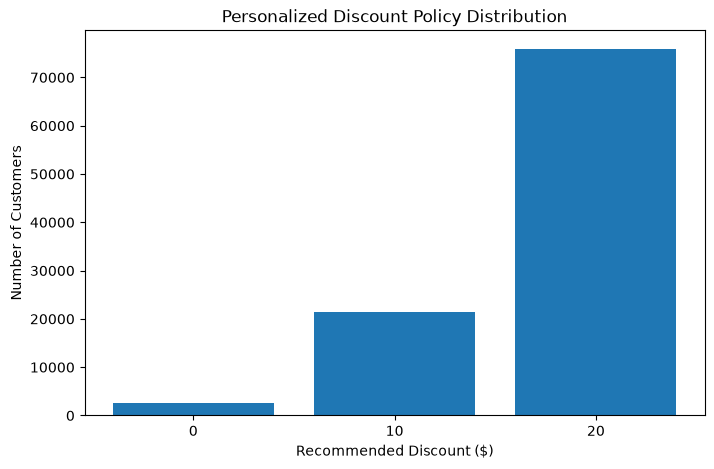

In [52]:
import matplotlib.pyplot as plt

policy_counts = df["recommended_discount"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    policy_counts.index.astype(str),
    policy_counts.values
)

plt.xlabel("Recommended Discount ($)")
plt.ylabel("Number of Customers")
plt.title("Personalized Discount Policy Distribution")
plt.show()

In [53]:
print(df.columns.tolist())

['customer_id', 'age', 'past_purchases', 'product_views', 'website_visits', 'avg_order_value', 'days_since_last_purchase', 'loyalty_score', 'cart_additions', 'email_engagement', 'customer_tenure', 'product_interest_score', 'previous_discount_usage', 'discount', 'purchase', 'ite_any_discount', 'ite_10_vs_0', 'ite_20_vs_0', 'ite_20_vs_10', 'baseline_probability_hat', 'p0_hat', 'p10_hat', 'p20_hat', 'ite_10_vs_0_all', 'ite_20_vs_0_all', 'profit_0_hat', 'profit_10_hat', 'profit_20_hat', 'recommended_discount', 'true_optimal_discount', 'persuadable', 'recommended_profit_hat', 'profit_gain_vs_no_discount']


In [54]:
policy_results = df[
    [
        "customer_id",
        "discount",
        "purchase",
        "p0_hat",
        "p10_hat",
        "p20_hat",
        "ite_10_vs_0_all",
        "ite_20_vs_0_all",
        "ite_20_vs_10",
        "profit_0_hat",
        "profit_10_hat",
        "profit_20_hat",
        "recommended_discount",
        "recommended_profit_hat",
        "profit_gain_vs_no_discount",
        "persuadable"
    ]
].copy()

policy_results.to_csv("../data/causal_policy_results.csv", index=False)

print("Policy results saved successfully")
print(policy_results.shape)

Policy results saved successfully
(100000, 16)


In [56]:
final_summary = pd.DataFrame({
    "Metric": [
        "Customers",
        "Policy accuracy",
        "Average profit without discount",
        "Average profit with personalized policy",
        "Average profit gain per customer",
        "Total estimated profit gain"
    ],
    "Value": [
        len(df),
        policy_accuracy,
        df["profit_0_hat"].mean(),
        df["recommended_profit_hat"].mean(),
        df["profit_gain_vs_no_discount"].mean(),
        df["profit_gain_vs_no_discount"].sum()
    ]
})

final_summary

,Metric,Value
0,Customers,1.000000e+05
1,Policy accuracy,8.917900e-01
2,Average profit without discount,1.814576e+02
3,Average profit with personalized policy,2.374317e+02
4,Average profit gain per customer,5.597411e+01
5,Total estimated profit gain,5.597411e+06


In [57]:
final_summary.to_csv("../data/causal_modeling_summary.csv", index=False)

print("Final summary saved successfully")

Final summary saved successfully
